# Discussion 4.1: Pretty Versus Practical
## Unigram and Bigram Frequency Analysis of the NIST AI Risk Management Framework (AI RMF 1.0)

**Data:** National Institute of Standards and Technology, *Artificial Intelligence Risk Management Framework (AI RMF 1.0)*, NIST AI 100-1, January 2023. 48-page PDF.

Keep `NIST.AI.100-1.pdf` in the same folder as this notebook so the relative path works.

## 1. Imports and one-time downloads

In [1]:
# pip install pypdf nltk matplotlib   (run once if needed)
import re
import string

import matplotlib.pyplot as plt
import nltk
from nltk import FreqDist, bigrams
from nltk.corpus import stopwords
from pypdf import PdfReader

nltk.download("stopwords", quiet=True)
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

True

## 2. Load the PDF
Each page carries a running header (`NIST AI 100-1 AI RMF 1.0`) and a page footer (`Page N`). Those are layout artifacts, not content, so they are stripped page by page before the text is combined. Leaving them in would add roughly 48 extra hits each to `nist`, `ai`, and `rmf`.

In [2]:
reader = PdfReader("NIST.AI.100-1.pdf")
print("Pages:", len(reader.pages))

pages = []
for page in reader.pages:
    t = page.extract_text()
    t = re.sub(r"^NIST AI 100-1 AI RMF 1\.0\s*", "", t)   # running header
    t = re.sub(r"Page \d+\s*$", "", t.strip())             # page footer
    pages.append(t)

raw_text = "\n".join(pages)
print("Raw word count:", len(raw_text.split()))
print(raw_text[3000:3600])

Pages: 48
Raw word count: 15569
es for the GOVERN function. 22
Table 2 Categories and subcategories for the MAP function. 26
Table 3 Categories and subcategories for the MEASURE function. 29
Table 4 Categories and subcategories for the MANAGE function. 32
i
List of Figures
Fig. 1 Examples of potential harms related to AI systems. Trustworthy AI systems
and their responsible use can mitigate negative risks and contribute to bene-
fits for people, organizations, and ecosystems. 5
Fig. 2 Lifecycle and Key Dimensions of an AI System. Modified from OECD
(2022) OECD Framework for the Classification of AI systems — OECD
Digital Eco


## 3. Data preparation
1. Rejoin words hyphenated across line breaks (`how-\never` becomes `however`).
2. Remove URLs and DOI links from the reference section.
3. Lowercase all text.
4. Replace curly quotes, dashes, and bullets, then remove standard punctuation.
5. Remove digits.
6. Tokenize.
7. Remove English stop words and single-character tokens.

In [3]:
text = re.sub(r"-\n(?=[a-z])", "", raw_text)                  # 1. fix line-break hyphenation
text = re.sub(r"https?://\S+|www\.\S+|doi\.org\S*", "", text)   # 2. URLs
text = text.lower()                                              # 3. lowercase
text = re.sub(r"[\u2013\u2014\u2018\u2019\u201c\u201d\u2022]", " ", text)  # 4a. unicode punctuation
text = text.translate(str.maketrans(string.punctuation, " " * len(string.punctuation)))  # 4b. punctuation
text = re.sub(r"\d+", " ", text)                                # 5. digits

tokens = nltk.word_tokenize(text)                                # 6. tokenize

stop_words = set(stopwords.words("english"))
tokens = [w for w in tokens if w.isalpha() and len(w) > 1 and w not in stop_words]  # 7.

print("Tokens after cleaning:", len(tokens))
print("Unique tokens:", len(set(tokens)))
print(tokens[:30])

Tokens after cleaning: 9629
Unique tokens: 1891
['nist', 'ai', 'artificial', 'intelligence', 'risk', 'management', 'framework', 'ai', 'rmf', 'nist', 'ai', 'artificial', 'intelligence', 'risk', 'management', 'framework', 'ai', 'rmf', 'publication', 'available', 'free', 'charge', 'january', 'department', 'commerce', 'gina', 'raimondo', 'secretary', 'national', 'institute']


## 4. Unigram frequency plot (top 20)

ai                651
risk              181
system            178
systems           163
risks             155
management        96
may               78
actors            73
rmf               72
function          68
map               60
organizations     59
use               58
impacts           56
measure           55
framework         52
manage            52
human             52
govern            51
data              51


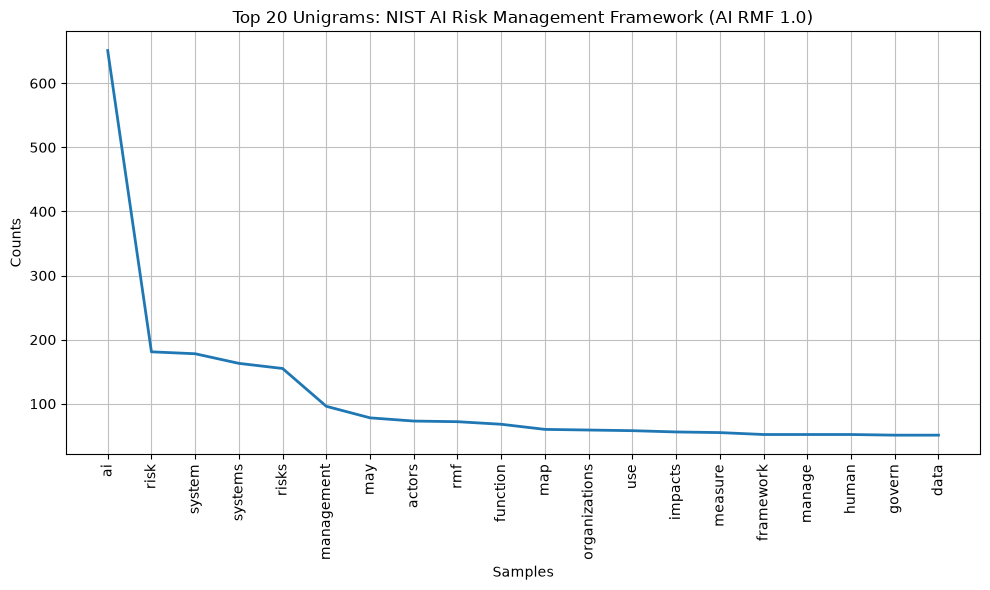

In [4]:
unigram_fd = FreqDist(tokens)
for word, count in unigram_fd.most_common(20):
    print(f"{word:<18}{count}")

plt.figure(figsize=(10, 6))
unigram_fd.plot(20, title="Top 20 Unigrams: NIST AI Risk Management Framework (AI RMF 1.0)", show=False)
plt.tight_layout()
plt.savefig("unigram_frequency.png", dpi=150)
plt.show()

## 5. Bigram frequency plot (top 20)

ai systems                    129
ai system                     116
risk management               79
ai rmf                        72
ai actors                     65
ai risks                      62
ai risk                       41
categories subcategories      39
ai lifecycle                  33
map function                  24
third party                   21
relevant ai                   19
negative impacts              18
managing ai                   17
end users                     16
table categories              15
trustworthy ai                15
design development            14
development deployment        14
risk tolerance                13


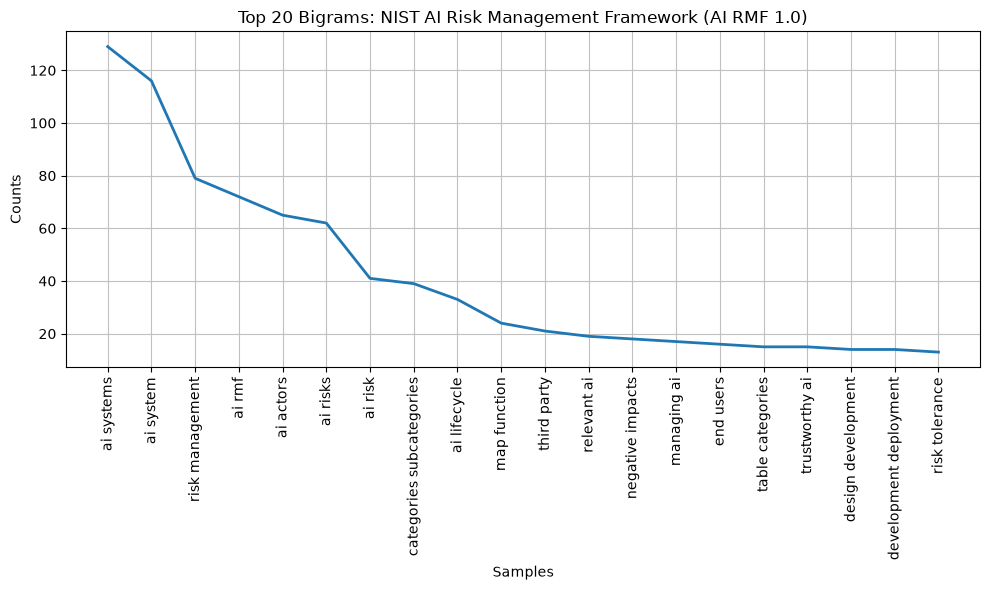

In [5]:
bigram_fd = FreqDist(bigrams(tokens))
for pair, count in bigram_fd.most_common(20):
    print(f"{' '.join(pair):<30}{count}")

# Join each pair into one label so the x-axis reads 'ai systems' instead of ('ai', 'systems')
bigram_labels = FreqDist({" ".join(k): v for k, v in bigram_fd.items()})

plt.figure(figsize=(10, 6))
bigram_labels.plot(20, title="Top 20 Bigrams: NIST AI Risk Management Framework (AI RMF 1.0)", show=False)
plt.tight_layout()
plt.savefig("bigram_frequency.png", dpi=150)
plt.show()

## 6. Observations
- `ai` dominates the unigrams, as expected for a framework about AI, and `risk`/`risks` plus `system`/`systems` confirm the subject.
- `govern`, `map`, `measure`, and `manage` all rank highly because they are the framework's four core functions.
- `may` survives stop-word removal. It is not in NLTK's list, and its frequency reflects the document's advisory, non-mandatory tone.
- `categories subcategories` and `table categories` come from table captions, which shows that PDF layout can leak into text analysis.
- Stemming or lemmatization would merge `system`/`systems` and `risk`/`risks` and push those counts even higher.

## Reference
[1] National Institute of Standards and Technology, "Artificial Intelligence Risk Management Framework (AI RMF 1.0)," U.S. Dept. of Commerce, Gaithersburg, MD, USA, NIST AI 100-1, Jan. 2023. [Online]. Available: https://doi.org/10.6028/NIST.AI.100-1